# 0.0 Imports

In [29]:
# Bibliotecas

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 0.1 Helper Function

## 0.2 Loading data

### 0.2.1 Data Train

In [30]:
df_raw = pd.read_csv('../dataset/train.csv')

In [31]:
df_raw.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [32]:
print('Number of rows: {}'.format(df_raw.shape[0]))
print('Number of columns: {}'.format(df_raw.shape[1]))

Number of rows: 699960
Number of columns: 26


In [33]:
# Colunas do DataFrame treino
df_raw.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [34]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [35]:
df_raw.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

### 0.2.2 Data Test

In [36]:
df_test = pd.read_csv('../dataset/test.csv')

In [37]:
df_test.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


In [38]:
# Número de linhas e colunas do DataFrame teste
print('Number of rows: {}'.format(df_test.shape[0]))
print('Number of columns: {}'.format(df_test.shape[1]))

Number of rows: 299984
Number of columns: 25


In [39]:
# Colunas do DataFrame teste
df_test.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

In [40]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            299984 non-null  int64  
 1   amount_usd                    299984 non-null  float64
 2   hours_since_last_txn          299984 non-null  float64
 3   txn_count_last_24h            299984 non-null  int64  
 4   distance_from_home_km         299984 non-null  float64
 5   card_age_months               299984 non-null  int64  
 6   customer_age                  299984 non-null  int64  
 7   account_balance_usd           299984 non-null  float64
 8   cvv_retry_count               299984 non-null  int64  
 9   velocity_score                299984 non-null  float64
 10  time_of_day_hour              299984 non-null  int64  
 11  day_of_week                   299984 non-null  int64  
 12  merchant_risk_score           299984 non-null  float64


In [41]:
df_test.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
dtype: int64

# 1.0 DESCRICAO DOS DADOS

In [42]:
df1 = df_raw.copy()

In [43]:
del (df_raw)

## 1.2 Data Dimensions

In [44]:
# Número de linhas e colunas do DataFrame treino
print('Number of rows: {}'.format(df1.shape[0]))
print('Number of columns: {}'.format(df1.shape[1]))

Number of rows: 699960
Number of columns: 26


## 1.3 Data Types

In [45]:
# Tipo de dados das colunas do DataFrame treino
df1.dtypes

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [46]:
# Tipo da variável alvo
df1['is_fraud'].unique()

array([0., 1.])

## 1.4 Descriptive Statistics

In [47]:
# Selecionando atributos numéricos e categóricos
numerical_att = df1.select_dtypes(include=['int64', 'float64']).drop(columns=['id'])
categorical_att = df1.select_dtypes(exclude=['int64', 'float64'])

In [48]:
display(numerical_att)

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,1,3,54.8,0,0.0
699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,5,1,43.9,0,0.0
699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,4,6,38.7,0,0.0
699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,12,3,32.3,0,0.0


In [49]:
# Estatísticas descritivas dos atributos categóricos
df1.describe(exclude=[np.int64,np.float64]).T

,count,unique,top,freq
merchant_category,699960,12,Online Retail,155097
card_type,699960,5,Visa,345001
auth_method,699960,5,3D Secure,210036
channel,699960,5,Online,273939
device_type,699960,8,Android Phone,237454
is_foreign_transaction,699960,2,False,687862
is_new_merchant,699960,2,False,593240
used_vpn,699960,2,False,676295
ip_country_mismatch,699960,2,False,688648
billing_shipping_mismatch,699960,2,False,690906


In [50]:
display(categorical_att)

,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False
1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False
2,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False
3,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False
4,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
699955,Travel,Mastercard,3D Secure,POS,Windows PC,False,False,False,False,False,False
699956,Restaurants,Mastercard,No Authentication,Online,iPhone,False,False,False,False,False,False
699957,Online Retail,Mastercard,Biometric,Online,Android Phone,False,False,True,False,False,False
699958,Groceries,Mastercard,PIN,ATM,Windows PC,False,False,True,False,False,False


## 1.4.1 Numerical Attributes

In [51]:
# Satisfação: 1.0 = satisfeitos, 0.0 = não satisfeitos
satisfaction_counts = df1['is_fraud'].value_counts()
print(f'Quantidade de fraudes: {satisfaction_counts[1.0]}')
print(f'Quantidade de não fraudes: {satisfaction_counts[0.0]}')

# Proporção de passageiros satisfeitos e insatisfeitos
satisfaction_proportion = df1['is_fraud'].value_counts(normalize=True)*100
print(f'Proporção de fraudes: {satisfaction_proportion[1.0]:.2f}%')
print(f'Proporção de não fraudes: {satisfaction_proportion[0.0]:.2f}%')

Quantidade de fraudes: 11689
Quantidade de não fraudes: 688271
Proporção de fraudes: 1.67%
Proporção de não fraudes: 98.33%


In [52]:
# Estatísticas descritivas dos atributos numéricos
display(numerical_att.describe().T)

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


In [53]:
# Central Tendency - mean, median
ct1 = pd.DataFrame(numerical_att.apply(np.mean)).T #média
ct2 = pd.DataFrame(numerical_att.apply(np.median)).T #mediana

In [54]:
# Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(numerical_att.apply(np.std)).T                      # desvio padrão
d2 = pd.DataFrame(numerical_att.apply(min)).T                         # min
d3 = pd.DataFrame(numerical_att.apply(max)).T                         # max
d4 = pd.DataFrame(numerical_att.apply(lambda x: x.max() - x.min())).T # range
d5 = pd.DataFrame(numerical_att.apply(lambda x: x.skew())).T          # skew
d6 = pd.DataFrame(numerical_att.apply(lambda x: x.kurtosis())).T      # kurtosis

# Concatenar os dataframes de tendência central e dispersão
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

# Dataframes de dispersão
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,amount_usd,1.00,6872.69,6871.69,79.893068,27.25,205.173392,7.002189,97.266330
1,hours_since_last_txn,0.01,51.98,51.97,6.633734,4.73,6.290128,1.823175,4.402021
2,txn_count_last_24h,0.00,11.00,11.00,2.984092,3.00,1.498997,0.436433,0.105677
3,distance_from_home_km,0.00,57.93,57.93,13.587575,10.22,11.617317,1.059740,0.450455
4,card_age_months,25.00,73.00,48.00,46.862982,47.00,5.579186,0.132970,-0.019347
5,customer_age,18.00,81.00,63.00,51.430286,52.00,17.899137,-0.140794,-1.045922
6,account_balance_usd,58.25,99701.39,99643.14,2064.998070,1382.74,3400.130493,14.436200,278.354033
7,cvv_retry_count,0.00,3.00,3.00,0.085472,0.00,0.289524,3.318657,10.534144
8,velocity_score,0.00,72.90,72.90,18.929445,18.60,10.864377,0.259673,-0.145117
9,time_of_day_hour,0.00,23.00,23.00,11.761915,12.00,6.869159,-0.056117,-1.184197


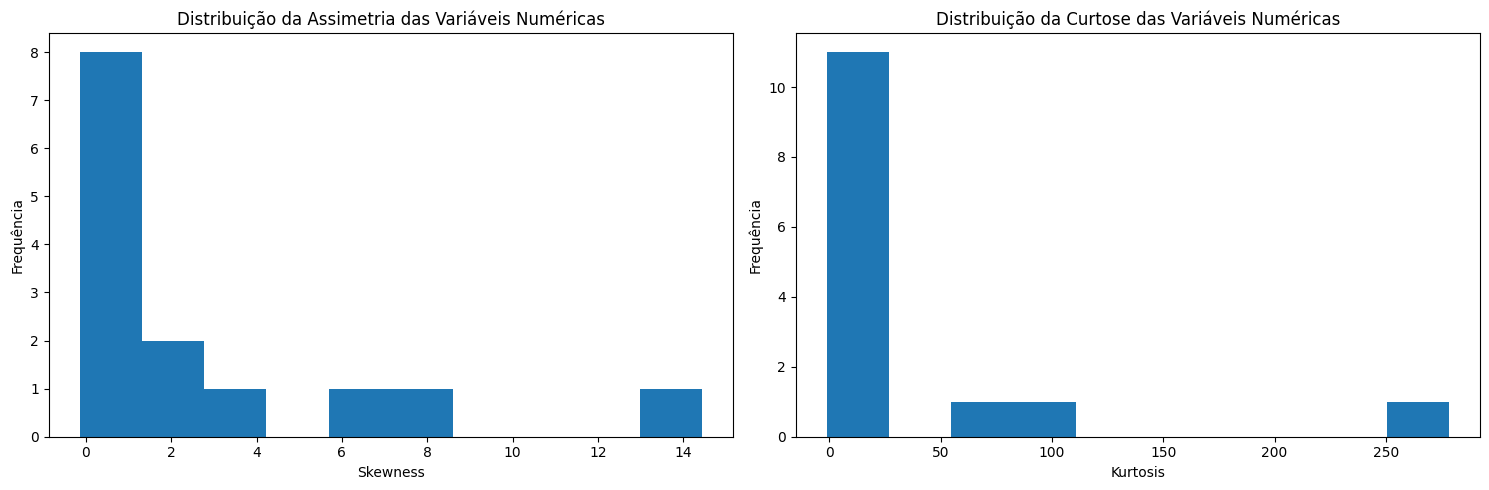

In [55]:
# Criar uma figura com 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma Skewness (Assimetria): negativo = cauda esquerda, positivo = cauda direita, 0 = simetria
axes[0].hist(d5.T.values.flatten(), bins=10)
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Assimetria das Variáveis Numéricas')
axes[0].set_xlabel('Skewness')

# Histograma Kurtosis (Curtose): relacionada ao comportamento das caudas e à ocorrência de valores extremos
axes[1].hist(d6.T.values.flatten(), bins=10)
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição da Curtose das Variáveis Numéricas')
axes[1].set_xlabel('Kurtosis')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 1.4.2 Categorical Attributes

In [56]:
categorical_att.apply(lambda x: x.unique().shape[0])

merchant_category               12
card_type                        5
auth_method                      5
channel                          5
device_type                      8
is_foreign_transaction           2
is_new_merchant                  2
used_vpn                         2
ip_country_mismatch              2
billing_shipping_mismatch        2
is_ai_generated_scam_attempt     2
dtype: int64

# 2.0 FEATURE ENGINEERING

## Mapa mental de hipóteses

- Fenômeno: Satisfação do cliente (variável dependente ou resposta = y).
- Agentes: Variáveis que impactam o fenômeno (variáveis independentes = x)
- Atributos do agente: características dos atributos.

## 2.1 Criação das hipóteses

### Hipóteses com dados disponíveis:
#### 2.1.1 Serviços de Conveniência

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

## 2.2 Lista final de hipóteses

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

### Feature Engineering

In [57]:
df2 = df1.copy()

In [58]:
#del (df1)

# 3.0 ANÁLISE EXPLORATÓRIA DOS DADOS - EDA

## 3.1 Análise Exploratória Univariada

### 3.1.1 Numerical Variable

### 3.1.2 Categorical Variables

## 3.2 Análise Exploratória Bivariada

## 3.3 Análise Multivariada

### 3.3.1 Numerical Attributes 

### 3.3.2 Categorical Attributes

# 4.0 Data Preparation 

## 4.1. Separação entre Treinamento e validação